# Stage 3: TLS figures

The TLS figures from the original plotting notebook, run on the 13 region objects from `stage3_TLS_regions.ipynb`.

Changes from the original notebook:
- Objects are read from `stage3_TLS_regions.ipynb` instead of the archived ones.
- The broad cell class composition plot is left out; it isn't used in the manuscript.
- `color_map`, `TLS_96_n2_subset`, `TLS_97_n2_subset` and `TNBC1` were used without being defined; they are defined below (marked *assumed* where they had to be reconstructed).
- `manual_colors` (the TNBC palette) is defined before its first use; the PDAC B-cell neighbour plots use `color_map`, because `manual_colors` has no colour for PDAC labels such as `TAMs_C1QC`; and the second SLS spatial plot (which had a syntax error) is left out.
- `Stromal_CCL19` is renamed `TRCs`, to match `stage3_TLS_regions.ipynb` and the rest of the analysis.
- The two Extended Data Fig. 9E plots are now saved (`TNBC4_TLS_PLA2G2A_IGF1.pdf` and `TNBC_stromal.pdf`), and the TCF7/LEF1/CCR7 Moran plot is saved as `Moran_#5.pdf`; both saved to `Moran_#4.pdf` before.
- Matplotlib figures are saved to `FIGURE_DIR`; scanpy and squidpy figures keep their original `save=` names.

**Saved outputs:** this notebook was run before `Stromal_CCL19` was renamed `TRCs`. The text outputs have been updated to `TRCs`, but the saved plot images still show `Stromal_CCL19`, which is the same label as `TRCs`. The two Extended Data Fig. 9E files and `Moran_#5.pdf` were added after the run, so they are written only on the next run.

## Parameters

In [1]:
import os

# The 13 objects from stage3_TLS_regions.ipynb
REGION_DIR = "/path/to/stage3_output/TLS_regions"
FIGURE_DIR = os.path.join(REGION_DIR, "figures")

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

import os
from collections import Counter
from scipy.spatial import cKDTree

os.makedirs(FIGURE_DIR, exist_ok=True)
sc.settings.figdir = FIGURE_DIR

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


## Load the region objects

In [3]:
load = lambda name: sc.read_h5ad(os.path.join(REGION_DIR, f"{name}.h5ad"))
TLS_107_314 = load("TLS_107_314")
TLS_104_314 = load("TLS_104_314")
TLS_065_314 = load("TLS_065_314")
TLS_096_480_n2 = load("TLS_096_480_n2")
TLS_096_480_n1 = load("TLS_096_480_n1")
TLS_097_480_n3 = load("TLS_097_480_n3")
TLS_097_480_n2 = load("TLS_097_480_n2")
TLS_097_480_n1 = load("TLS_097_480_n1")
SLS_ref = load("SLS_ref")
TLS_TNBC_1 = load("TNBC_1")
TLS_TNBC_2 = load("TNBC_2")
TLS_TNBC_3 = load("TNBC_3")
TLS_TNBC_4 = load("TNBC_4")

## Colours

In [4]:
manual_colors = {
   'B cells':  '#ff7f0e',
    'myCAFs': '#FFE5A7', #'#c7c7c7',
    'iCAFs': "#B4584D",
    "CD4 T cells":  '#7d87b9',
    "CD4 Tfh" : "#46487E",
    "CD8 T cells":'#023fa5',
    "DC1": "#888D07",
    "DC2": "#717417", 
    "Myoepithelial": '#f3e1eb',#'#00846f',
    "Endothelial":'#d62728',
    "FRCs": "#00BFA0",
    "LECs": "#535A06",
    "Malignant cells": '#8c564b',
    "Mast": '#000035',
    "Migratory DCs": "#105354",
    "NK": "#00025E",
    "Neutrophils": '#b903aa',
    "Pericytes": '#d5eae7', #'#c5b0d5',
    "Plasma": '#9cded6',
    "SMCs": '#d5eae7', #'#c5b0d5',
    "Schwann": '#b79762',
    "MAC_SIGLEC1":'#c5b0d5',
    "TAMs_MHC": "#5E21E3",
    "TAMs_OLR1":'#e377c2',
    "TAMs_SPP1": '#17becf',
    "Unclassified": "#cccccc",
    "pDCs":'#1b4400',
    'TRCs': '#D8D18C', 
    "Other": "#cccccc"
}

# color_map was used for the composition bar plots without being defined in TLS_plotting_final.ipynb.
# Assumed: manual_colors plus the TLS labels it doesn't cover; replace with the original if you have it.
color_map = {
    **manual_colors,
    'FDCs': "#DD51AD", 'CD4 Treg': '#006fa6', 'CAFs_MYO': '#c7c7c7', 'CAFs_CXCL14': '#ff34ff',
    'CAFs_NRT': '#b5bd61', 'TAMs_C1QC': '#e377c2', 'gdT': '#a30059',
}

## Sample lists

In [5]:
tls_list = [
    TLS_107_314, TLS_104_314, TLS_065_314, TLS_096_480_n2,
    TLS_096_480_n1,TLS_097_480_n3,TLS_097_480_n2,TLS_097_480_n1,SLS_ref
]
# Initialize lists to hold counts
tls_names = [
    "TLS_107_314", "TLS_104_314","TLS_065_314","TLS_096_480_n2",
    "TLS_096_480_n1","TLS_097_480_n3","TLS_097_480_n2","TLS_097_480_n1","SLS_ref"
]
tls_data = {
    "TLS_107_314": TLS_107_314.obs["TLS_cell_class_threshold"],
    "TLS_104_314": TLS_104_314.obs["TLS_cell_class_threshold"],
    "TLS_065_314": TLS_065_314.obs["TLS_cell_class_threshold"],
    "TLS_096_480_n2": TLS_096_480_n2.obs["TLS_cell_class_threshold"],
    "TLS_096_480_n1": TLS_096_480_n1.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n3": TLS_097_480_n3.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n2": TLS_097_480_n2.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n1": TLS_097_480_n1.obs["TLS_cell_class_threshold"],
}

# Build long-form DataFrame
df_all = pd.concat(
    [pd.DataFrame({"TLS_ID": tls_id, "cell_type": values}) for tls_id, values in tls_data.items()],
    ignore_index=True
)

In [6]:
tnbc_list = [TLS_TNBC_1, TLS_TNBC_2, TLS_TNBC_3, TLS_TNBC_4]
tnbc_names = ["TNBC_1","TNBC_2","TNBC_3", "TNBC_4"]
tnbc_data = {
    "TNBC_1": TLS_TNBC_1.obs["TLS_cell_class_threshold"],
    "TNBC_2": TLS_TNBC_2.obs["TLS_cell_class_threshold"],
    "TNBC_3": TLS_TNBC_3.obs["TLS_cell_class_threshold"],
    "TNBC_4": TLS_TNBC_4.obs["TLS_cell_class_threshold"],
   
}

# Build long-form DataFrame
df_tnbc = pd.concat(
    [pd.DataFrame({"TLS_ID": tls_id, "cell_type": values}) for tls_id, values in tnbc_data.items()],
    ignore_index=True
)

In [7]:
merged_data = {
    "TLS_107_314": TLS_107_314.obs["TLS_cell_class_threshold"],
    "TLS_104_314": TLS_104_314.obs["TLS_cell_class_threshold"],
    "TLS_065_314": TLS_065_314.obs["TLS_cell_class_threshold"],
    "TLS_096_480_n2": TLS_096_480_n2.obs["TLS_cell_class_threshold"],
    "TLS_096_480_n1": TLS_096_480_n1.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n3": TLS_097_480_n3.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n2": TLS_097_480_n2.obs["TLS_cell_class_threshold"],
    "TLS_097_480_n1": TLS_097_480_n1.obs["TLS_cell_class_threshold"],
    "SLS_ref": SLS_ref.obs["TLS_cell_class_threshold"],
    "TNBC_1": TLS_TNBC_1.obs["TLS_cell_class_threshold"],
    "TNBC_2": TLS_TNBC_2.obs["TLS_cell_class_threshold"],
    "TNBC_3": TLS_TNBC_3.obs["TLS_cell_class_threshold"],
    "TNBC_4": TLS_TNBC_4.obs["TLS_cell_class_threshold"],
}

# Build long-form DataFrame
df_merged = pd.concat(
    [pd.DataFrame({"TLS_ID": tls_id, "cell_type": values}) for tls_id, values in merged_data.items()],
    ignore_index=True)

## Cellular composition across TLSs in PDAC

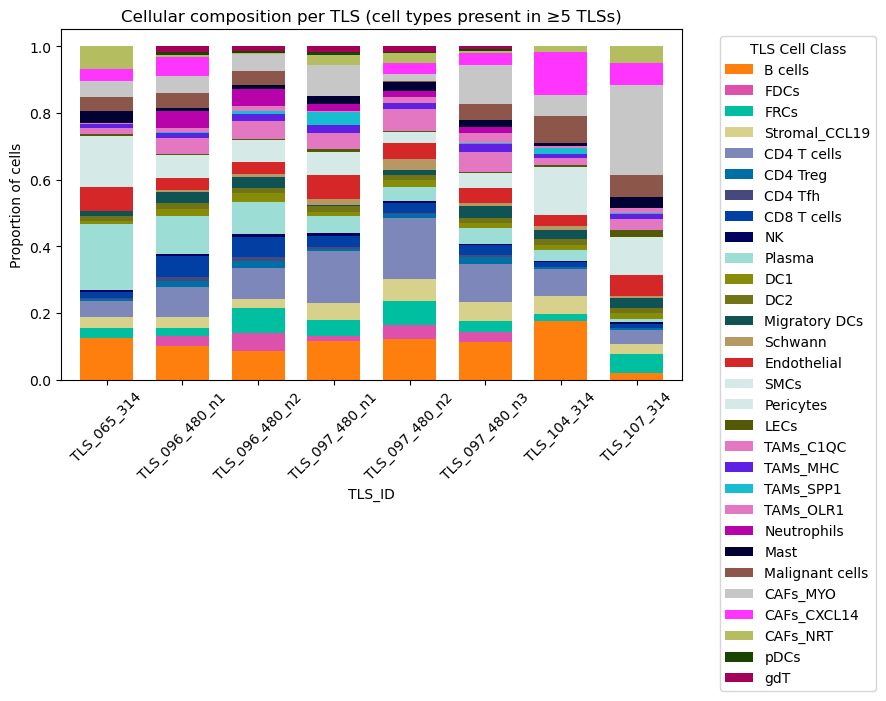

In [8]:
# Count presence of each cell type across TLSs
tls_presence = df_all.drop_duplicates().groupby("cell_type")["TLS_ID"].nunique()

# Keep only those present in ≥5 TLSs
# Remove 'Unclassified' or 'Unassigned'
consistent_cell_types = [
    c for c in tls_presence[tls_presence >= 5].index
    if c not in ['Unclassified', 'Unassigned']
]

# Filter original DataFrame
df_filtered = df_all[df_all["cell_type"].isin(consistent_cell_types)]

comp = (
    df_filtered.groupby(["TLS_ID", "cell_type"])
    .size()
    .reset_index(name="count")
)

comp["proportion"] = comp.groupby("TLS_ID")["count"].transform(lambda x: x / x.sum())

# Pivot for plotting
pivot = comp.pivot(index="TLS_ID", columns="cell_type", values="proportion").fillna(0)

# order classes
ordered_classes = consistent_cell_types
pivot = pivot[ordered_classes[::-1]]  # reverse for stacking order

custom_order = [ 'B cells', 'FDCs', 'FRCs', 'TRCs',  'CD4 T cells','CD4 Treg', 'CD4 Tfh',
                'CD8 T cells','NK', 'Plasma', 'DC1', 'DC2', 'Migratory DCs', 
                'Schwann', 'Endothelial','SMCs',  'Pericytes','LECs',
                'TAMs_C1QC', 'TAMs_MHC', 'TAMs_SPP1', 'TAMs_OLR1','Neutrophils','Mast', 'Malignant cells', 
                 'CAFs_MYO', 'CAFs_CXCL14','CAFs_NRT','pDCs', 'gdT'
]

# Keep only those that are present in pivot
custom_order = [c for c in custom_order if c in pivot.columns]

# Reorder pivot
pivot = pivot[custom_order]

# Plot
pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    width=0.7,
    color=[color_map[c] for c in pivot.columns]
)

plt.ylabel("Proportion of cells")
plt.title("Cellular composition per TLS (cell types present in ≥5 TLSs)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='TLS Cell Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "TLS_composition_PDAC.pdf"), bbox_inches="tight")
plt.show()
pivot.to_csv(os.path.join(FIGURE_DIR, "TLS_composition_PDAC.tsv"), sep="\t")

### Schwann cells in PDAC TLS - Extended Data Fig 9f

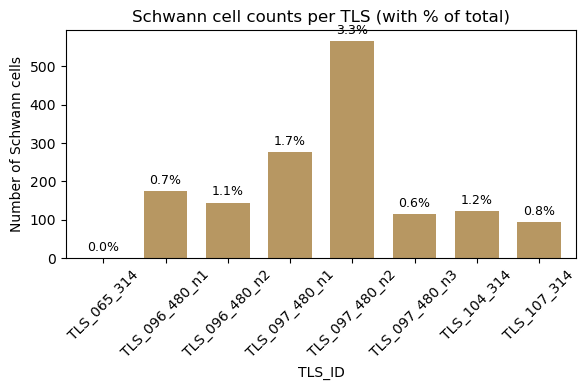

In [9]:
# Counts
schwann_counts = (
    comp[comp["cell_type"] == "Schwann"]
    .set_index("TLS_ID")["count"]
    .reindex(pivot.index, fill_value=0)   # include all TLSs
)

# Percentages (×100 for %)
schwann_perc = pivot["Schwann"] * 100

# Plot counts
ax = schwann_counts.plot(
    kind="bar",
    figsize=(6,4),
    color="#b79762",   # Schwann colour
    width=0.7
)

# Add percentage labels above bars
for i, (count, perc) in enumerate(zip(schwann_counts, schwann_perc)):
    ax.text(i, count + max(schwann_counts)*0.02,   # just above bar
            f"{perc:.1f}%", 
            ha="center", va="bottom", fontsize=9)

plt.ylabel("Number of Schwann cells")
plt.xlabel("TLS_ID")
plt.title("Schwann cell counts per TLS (with % of total)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "Schwann_counts.pdf"), bbox_inches="tight")
plt.show()

## Cellular composition across lymph node, TLS in PDAC and TLS in TNBC - NOT USED

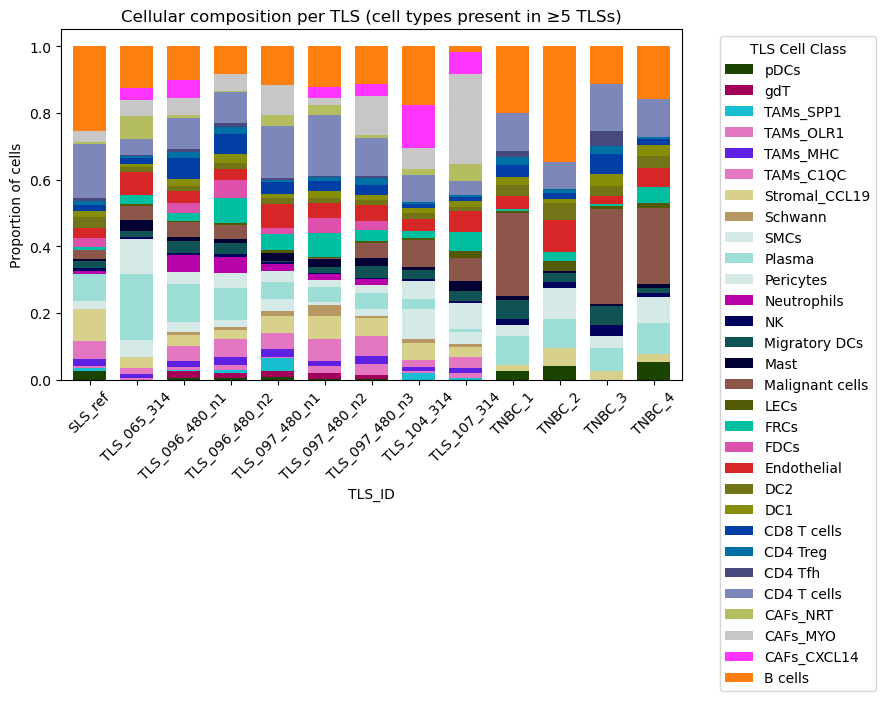

In [10]:
# Filter original DataFrame
df_filtered = df_merged[df_merged["cell_type"].isin(consistent_cell_types)]

# Count & normalize per TLS
comp = (
    df_filtered.groupby(["TLS_ID", "cell_type"])
    .size()
    .reset_index(name="count")
)

comp["proportion"] = comp.groupby("TLS_ID")["count"].transform(lambda x: x / x.sum())

# Pivot for plotting
pivot = comp.pivot(index="TLS_ID", columns="cell_type", values="proportion").fillna(0)

ordered_classes = consistent_cell_types
pivot = pivot[ordered_classes[::-1]]  # reverse for stacking order

# Plot
pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    width=0.7,
    color=[color_map[c] for c in pivot.columns]
)

plt.ylabel("Proportion of cells")
plt.title("Cellular composition per TLS (cell types present in ≥5 TLSs)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='TLS Cell Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "TLS_composition_all.pdf"), bbox_inches="tight")
plt.show()
pivot.to_csv(os.path.join(FIGURE_DIR, "TLS_composition_all.tsv"), sep="\t")

## Neighbourhood around B cells (50 µm) in PDAC TLS and the lymph node

The neighbour function is the one in `stage3_tuft.ipynb`.

In [11]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from collections import Counter

def analyze_neighbors_avg_per_cell_type(
    adata,
    radius=50,
    label_key="cell_class_threshold",
    spatial_key="spatial",
    center_label="Tuft",
    exclude_labels=["Unclassified", "Unassigned"]
):
    """
    Analyze neighborhood composition around each tuft cell,
    averaging over all tuft cells in the sample.

    Parameters:
    -----------
    adata : AnnData
        Annotated data matrix with spatial coordinates and cell type labels.
    radius : float
        Radius (in micrometers) to define the neighborhood.
    label_key : str
        Key in adata.obs for cell type labels.
    spatial_key : str
        Key in adata.obsm for spatial coordinates.
    center_label : str
        Cell type to use as center (typically "Malignant").
    exclude_labels : list of str
        Cell types to exclude from neighbor composition.

    Returns:
    --------
    pd.Series
        Average neighborhood composition per malignant cell (as fractions).
    """
    coords = adata.obsm[spatial_key]
    labels = adata.obs[label_key]
    tree = cKDTree(coords)

    indices = np.where(labels == center_label)[0]
    per_cell_compositions = []

    for idx in indices:
        center = coords[idx]
        nearby_idx = tree.query_ball_point(center, r=radius)

        # Exclude self label and other unwanted categories
        neighbor_labels = [
            t for t in labels.iloc[nearby_idx]
            if t not in exclude_labels and t != center_label
        ]

        if neighbor_labels:
            counts = Counter(neighbor_labels)
            total = sum(counts.values())
            composition = {k: v / total for k, v in counts.items()}
            per_cell_compositions.append(composition)

    if not per_cell_compositions:
        return pd.Series(dtype=float)

    avg_df = pd.DataFrame(per_cell_compositions).fillna(0)
    return avg_df.mean()

In [12]:
results_by_sample = {}

# Loop over all samples
for adata, sample_name in zip(tls_list, tls_names):
    print(f"Processing {sample_name}...")

    df = analyze_neighbors_avg_per_cell_type(
        adata=adata,
        center_label="B cells",
        radius=50,
        label_key="TLS_cell_class_threshold",
        spatial_key="spatial"
    )

    results_by_sample[sample_name] = df

Processing TLS_107_314...
Processing TLS_104_314...
Processing TLS_065_314...
Processing TLS_096_480_n2...
Processing TLS_096_480_n1...
Processing TLS_097_480_n3...
Processing TLS_097_480_n2...
Processing TLS_097_480_n1...
Processing SLS_ref...


## B cell neighbourhood composition - Fig 6b

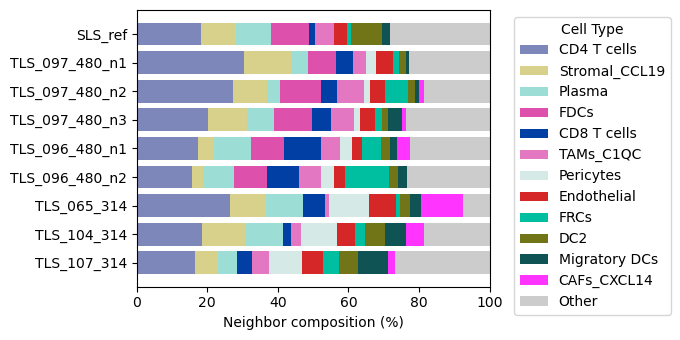

In [13]:
# Extract rows for malignant neighborhood composition
combined = []
for sample_name, series in results_by_sample.items():
    if isinstance(series, pd.Series):
        series.name = sample_name
        combined.append(series)

summary_df = pd.DataFrame(combined).fillna(0)

# Remove 'Unclassified'
if "Unclassified" in summary_df.columns:
    summary_df = summary_df.drop(columns=["Unclassified"])

# Find top cell types across all samples
top_cell_types = summary_df.sum().sort_values(ascending=False).head(12).index

# Collapse others into 'Other'
collapsed = summary_df[top_cell_types].copy()
collapsed["Other"] = summary_df.drop(columns=top_cell_types).sum(axis=1)

# Estimate total malignant cells from relative fraction sum
total_cells = {sample: int(row.sum() * 100) for sample, row in summary_df.iterrows()}

# Plot
fig, ax = plt.subplots(figsize=(7, 3.5))
bottom = np.zeros(len(collapsed))
y_pos = np.arange(len(collapsed))

for ct in collapsed.columns:
    values = collapsed[ct].values * 100
    ax.barh(y_pos, values, left=bottom, label=ct, color=color_map.get(ct, "#cccccc"))
    bottom += values

# Final plot formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(collapsed.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Neighbor composition (%)")
ax.legend(title="Cell Type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "B_neighbours_PDAC.pdf"), bbox_inches="tight")
plt.show()

## B cell neighbourhood composition

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


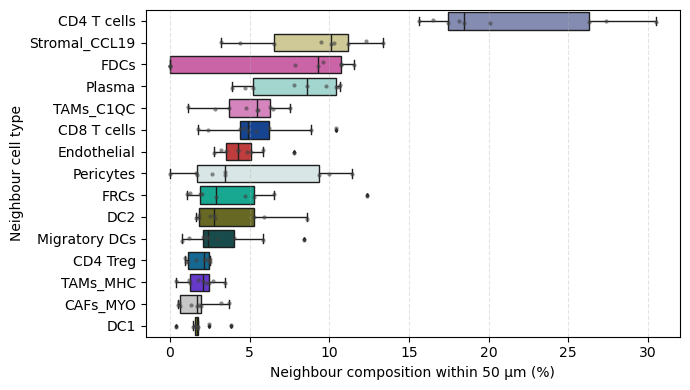

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

wide = pd.DataFrame(results_by_sample).T  # rows = samples, cols = neighbors (fractions)
wide = wide.fillna(0)

if any(col.endswith("_mean") for col in wide.columns):
    wide = wide[[c for c in wide.columns if c.endswith("_mean")]].copy()
    wide.columns = [c[:-5] for c in wide.columns]  # remove "_mean"

# Drop unwanted labels 
wide = wide.drop(columns=[c for c in ["Unclassified", "Unassigned"] if c in wide.columns], errors="ignore")
wide_pct = wide * 100

# Rank neighbors by median across samples
med_across_samples = wide_pct.median(axis=0).sort_values(ascending=False)

# Keep top cell types to show
topk = med_across_samples.head(min(15, len(med_across_samples))).index.tolist()

# Long format for plotting (only top k neighbors)
long = (
    wide_pct[topk]
    .reset_index()
    .rename(columns={"index": "sample"})
    .melt(id_vars="sample", var_name="neighbor", value_name="percent")
)

# Order neighbors by their cross-sample median
order = med_across_samples.loc[topk].index.tolist()

# Plotting
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=long, x="percent", y="neighbor",
    palette=color_map,
    order=order, fliersize=2, linewidth=1
)
sns.stripplot(
    data=long, x="percent", y="neighbor",
    order=order, color=".25", size=3, jitter=True, alpha=0.6
)
plt.xlabel("Neighbour composition within 50 µm (%)")
plt.ylabel("Neighbour cell type")
plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "B_neighbours_PDAC_boxplot.pdf"), bbox_inches="tight")
plt.show()
wide_pct.to_csv(os.path.join(FIGURE_DIR, "B_neighbours_PDAC.tsv"), sep="\t")

## Neighbourhood enrichment across PDAC TLS - Fig 6f

In [16]:
# Assume: a dictionary of samples
tls_dict = {
    "TLS_107_314": TLS_107_314,
    "TLS_104_314": TLS_104_314,
    "TLS_065_314": TLS_065_314,
    "TLS_096_480_n2": TLS_096_480_n2,
    "TLS_096_480_n1": TLS_096_480_n1,
    "TLS_097_480_n3": TLS_097_480_n3,
    "TLS_097_480_n2": TLS_097_480_n2,
    "TLS_097_480_n1": TLS_097_480_n1,
    #"SLS_ref": SLS_ref,
}
z_matrices = {}
for name, ad in tls_dict.items():
    z = ad.uns["TLS_cell_class_threshold_nhood_enrichment"]["zscore"]
    labels = ad.obs["TLS_cell_class_threshold"].cat.categories
    z_df = pd.DataFrame(z, index=labels, columns=labels)
    z_matrices[name] = z_df
    
# Stack each matrix, add sample name, and combine
z_long_list = []
for sample_name, z_df in z_matrices.items():
    z_long = z_df.stack().reset_index()
    z_long.columns = ["cluster_1", "cluster_2", "zscore"]
    z_long["sample"] = sample_name
    z_long_list.append(z_long)

z_combined = pd.concat(z_long_list, ignore_index=True)

In [17]:
# Define target cell types and thresholds
#target_types = ["FDCs", "FRCs", "TRCs"]
target_types = ["FDCs", "FRCs", "TRCs","Migratory DCs", "TAMs_C1QC","CAFs_NRT"]

min_samples = 3
score_threshold = 0.5

top_neighbors_by_type = {}

for cell_type in z_combined["cluster_1"].unique():
    if cell_type not in target_types:
        continue

    df = z_combined[z_combined["cluster_1"] == cell_type].copy()
    df = df[~df["cluster_2"].isin(["Unassigned", "Unclassified"])]
    df = df[df["cluster_1"] != df["cluster_2"]]

    # Normalize per sample
    df["zscore_minmax"] = df.groupby("sample")["zscore"].transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )

    # Aggregate
    agg = (
        df.groupby("cluster_2")
        .agg(
            mean_score=("zscore_minmax", "mean"),
            n_samples=("sample", "nunique")
        )
        .reset_index()
    )

    # Apply both filters
    agg = agg[(agg["n_samples"] >= min_samples) & (agg["mean_score"] >= score_threshold)]

    # Pick top neighbors by score
    top_n =4
    top_neighbors_by_type[cell_type] = agg.sort_values("mean_score", ascending=False).head(top_n)

In [18]:
# Combine results into a single DataFrame
top_neighbors_df = (
    pd.concat(top_neighbors_by_type, names=["Cell_Type"])
    .reset_index()
    .rename(columns={"cluster_2": "Neighbor", "n_samples": "Samples_enriched_in"})
)

top_neighbors_df = top_neighbors_df.sort_values(
    ["Cell_Type", "Samples_enriched_in"],
    ascending=[True, False]
)

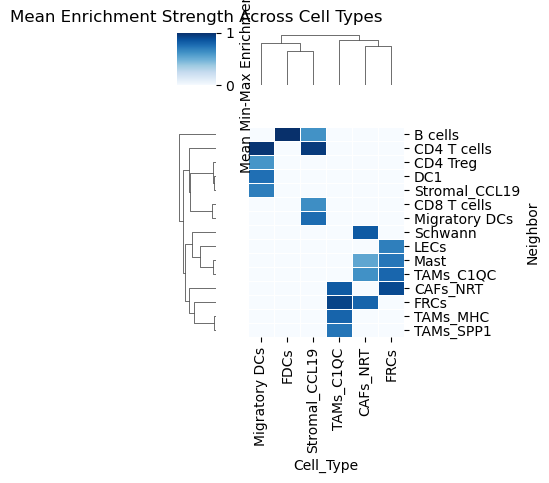

In [19]:
heatmap_scores = top_neighbors_df.pivot(
    index="Neighbor", columns="Cell_Type", values="mean_score"
).fillna(0)

sns.clustermap(
    heatmap_scores,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    row_cluster=True,
    col_cluster=True,
    figsize=(4, 5),
    cbar_kws={"label": "Mean Min-Max Enrichment Score"}
)
plt.title("Mean Enrichment Strength Across Cell Types", y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "Nhood_enrichment_PDAC.pdf"), bbox_inches="tight")
plt.show()
heatmap_scores.to_csv(os.path.join(FIGURE_DIR, "Nhood_enrichment_PDAC.tsv"), sep="\t")

## TLS in TNBC: neighbourhood around B cells - Extended Data Fig 9d

In [20]:
results_by_sample = {}

# Loop over all samples
for adata, sample_name in zip(tnbc_list, tnbc_names):
    print(f"Processing {sample_name}...")

    df = analyze_neighbors_avg_per_cell_type(
        adata=adata,
        center_label="B cells",
        radius=50,
        label_key="TLS_cell_class_threshold",
        spatial_key="spatial"
    )

    results_by_sample[sample_name] = df

Processing TNBC_1...
Processing TNBC_2...
Processing TNBC_3...
Processing TNBC_4...


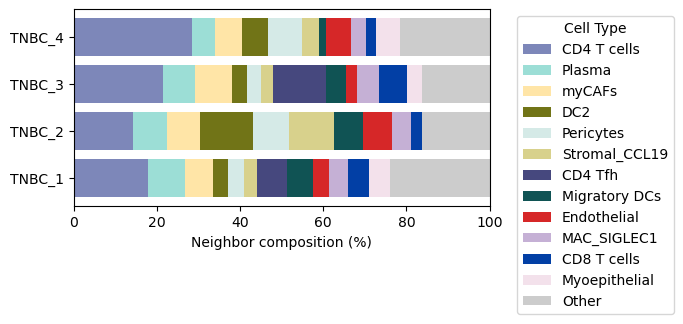

In [21]:
# Extract rows for malignant neighborhood composition
combined = []
for sample_name, series in results_by_sample.items():
    if isinstance(series, pd.Series):
        series.name = sample_name
        combined.append(series)

summary_df = pd.DataFrame(combined).fillna(0)

# Remove 'Unclassified' 
if "Unclassified" in summary_df.columns:
    summary_df = summary_df.drop(columns=["Unclassified"])

# Find top 6 cell classes
top_cell_types = summary_df.sum().sort_values(ascending=False).head(12).index

# Collapse others into 'Other'
collapsed = summary_df[top_cell_types].copy()
collapsed["Other"] = summary_df.drop(columns=top_cell_types).sum(axis=1)

# Estimate total malignant cells from relative fraction sum
total_cells = {sample: int(row.sum() * 100) for sample, row in summary_df.iterrows()}

# Plot
fig, ax = plt.subplots(figsize=(7, 3))
bottom = np.zeros(len(collapsed))
y_pos = np.arange(len(collapsed))

for ct in collapsed.columns:
    values = collapsed[ct].values * 100
    ax.barh(y_pos, values, left=bottom, label=ct, color=manual_colors.get(ct, "#cccccc"))
    bottom += values

# Final plot formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(collapsed.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Neighbor composition (%)")
ax.legend(title="Cell Type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "B_neighbours_TNBC.pdf"), bbox_inches="tight")
plt.show()

Original cell numbers: TLS_TNBC_1 54,017, TLS_TNBC_2 33,210, TLS_TNBC_3 46,852, TLS_TNBC_4 38,315 (172,394 in total).

In [22]:
adatas = [TLS_TNBC_1, TLS_TNBC_2, TLS_TNBC_3, TLS_TNBC_4]
expected = [54017, 33210, 46852, 38315]
tnbc_counts = pd.DataFrame({
    "region": [f"TLS_TNBC_{i}" for i in range(1, 5)],
    "cells": [a.n_obs for a in adatas],
    "cells_original": expected,
})
tnbc_counts["same"] = tnbc_counts["cells"] == tnbc_counts["cells_original"]
tnbc_counts.to_csv(os.path.join(FIGURE_DIR, "TNBC_cell_counts.tsv"), sep="\t", index=False)
print(tnbc_counts)
print("Combined:", tnbc_counts["cells"].sum(), "cells")

       region  cells  cells_original  same
0  TLS_TNBC_1  54017           54017  True
1  TLS_TNBC_2  33210           33210  True
2  TLS_TNBC_3  46852           46852  True
3  TLS_TNBC_4  38315           38315  True
Combined: 172394 cells


## Neighbourhood enrichment across TNBC TLS (n=4) - Extended Data Fig 9i

In [23]:
# Assume: a dictionary of samples
tnbc_dict = {
    "TNBC_1": TLS_TNBC_1,
    "TNBC_2": TLS_TNBC_2,
    "TNBC_3": TLS_TNBC_3,
    "TNBC_4": TLS_TNBC_4,
   
}
z_matrices = {}
for name, ad in tnbc_dict.items():
    z = ad.uns["TLS_cell_class_threshold_nhood_enrichment"]["zscore"]
    labels = ad.obs["TLS_cell_class_threshold"].cat.categories
    z_df = pd.DataFrame(z, index=labels, columns=labels)
    z_matrices[name] = z_df
    
# Stack each matrix, add sample name, and combine
z_long_list = []
for sample_name, z_df in z_matrices.items():
    z_long = z_df.stack().reset_index()
    z_long.columns = ["cluster_1", "cluster_2", "zscore"]
    z_long["sample"] = sample_name
    z_long_list.append(z_long)

z_combined = pd.concat(z_long_list, ignore_index=True)

In [24]:
# Define target cell types and thresholds
#target_types = ["FDCs", "FRCs", "TRCs"]
target_types = [ "FRCs", "TRCs","DC1","DC2","Migratory DCs", "MAC_SIGLEC1","B cells"]

min_samples = 2
score_threshold = 0.5

top_neighbors_by_type = {}

for cell_type in z_combined["cluster_1"].unique():
    if cell_type not in target_types:
        continue

    df = z_combined[z_combined["cluster_1"] == cell_type].copy()
    df = df[~df["cluster_2"].isin(["Unassigned", "Unclassified"])]
    df = df[df["cluster_1"] != df["cluster_2"]]

    # Normalize per sample
    df["zscore_minmax"] = df.groupby("sample")["zscore"].transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )

    # Aggregate
    agg = (
        df.groupby("cluster_2")
        .agg(
            mean_score=("zscore_minmax", "mean"),
            n_samples=("sample", "nunique")
        )
        .reset_index()
    )

    # Apply both filters
    agg = agg[(agg["n_samples"] >= min_samples) & (agg["mean_score"] >= score_threshold)]

    # Pick top neighbors by score
    top_n =3
    top_neighbors_by_type[cell_type] = agg.sort_values("mean_score", ascending=False).head(top_n)

In [25]:
# Combine results into a single DataFrame
top_neighbors_df = (
    pd.concat(top_neighbors_by_type, names=["Cell_Type"])
    .reset_index()
    .rename(columns={"cluster_2": "Neighbor", "n_samples": "Samples_enriched_in"})
)

# Optional: sort for readability
top_neighbors_df = top_neighbors_df.sort_values(
    ["Cell_Type", "Samples_enriched_in"],
    ascending=[True, False]
)

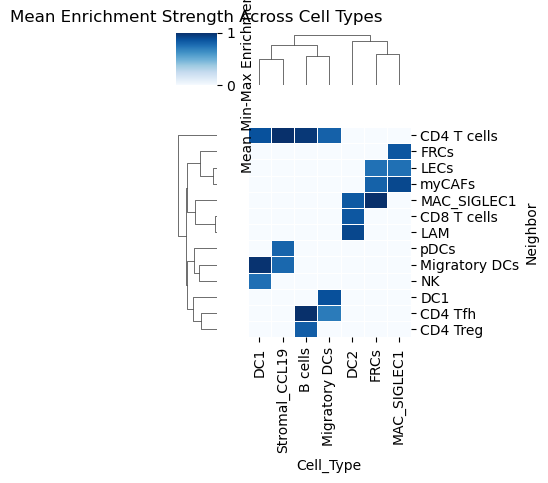

In [26]:
heatmap_scores = top_neighbors_df.pivot(
    index="Neighbor", columns="Cell_Type", values="mean_score"
).fillna(0)

sns.clustermap(
    heatmap_scores,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    row_cluster=True,
    col_cluster=True,
    figsize=(4, 5),
    cbar_kws={"label": "Mean Min-Max Enrichment Score"}
)
plt.title("Mean Enrichment Strength Across Cell Types", y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "Nhood_enrichment_TNBC.pdf"), bbox_inches="tight")
plt.show()
heatmap_scores.to_csv(os.path.join(FIGURE_DIR, "Nhood_enrichment_TNBC.tsv"), sep="\t")

## Genes with significant Moran's I score (MH097 n2)

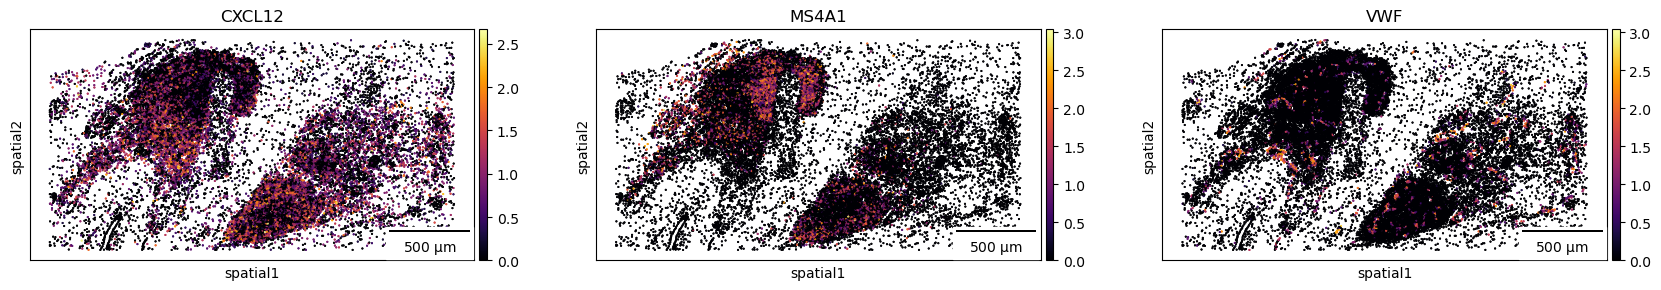

In [32]:
sq.pl.spatial_scatter(
    TLS_097_480_n2,
    library_id="spatial",
    color=['CXCL12','MS4A1','VWF'],
    shape=None,
    size=1,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='Moran_#4.pdf'
)

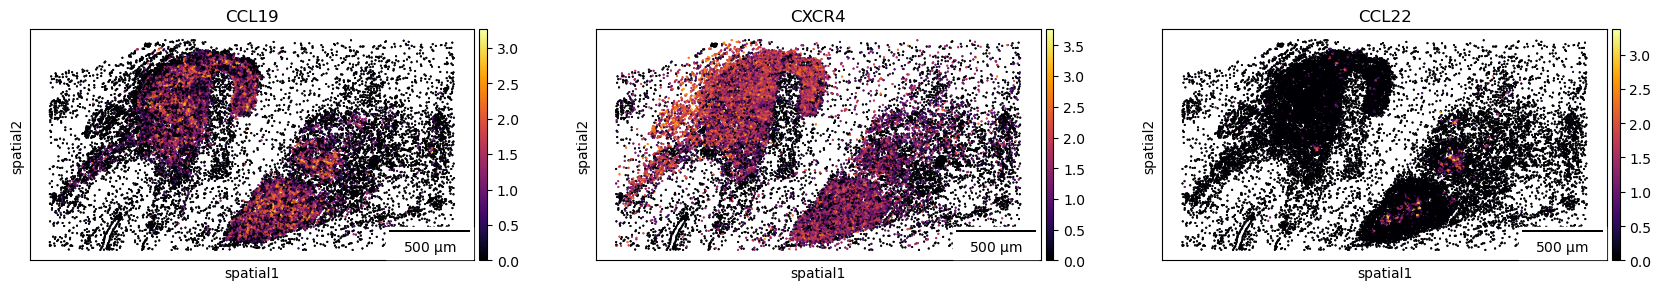

In [36]:
sq.pl.spatial_scatter(
    TLS_097_480_n2,
    library_id="spatial",
    color=['CCL19','CXCR4','CCL22'],
    shape=None,
    size=1,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='Moran_#2.pdf'
)

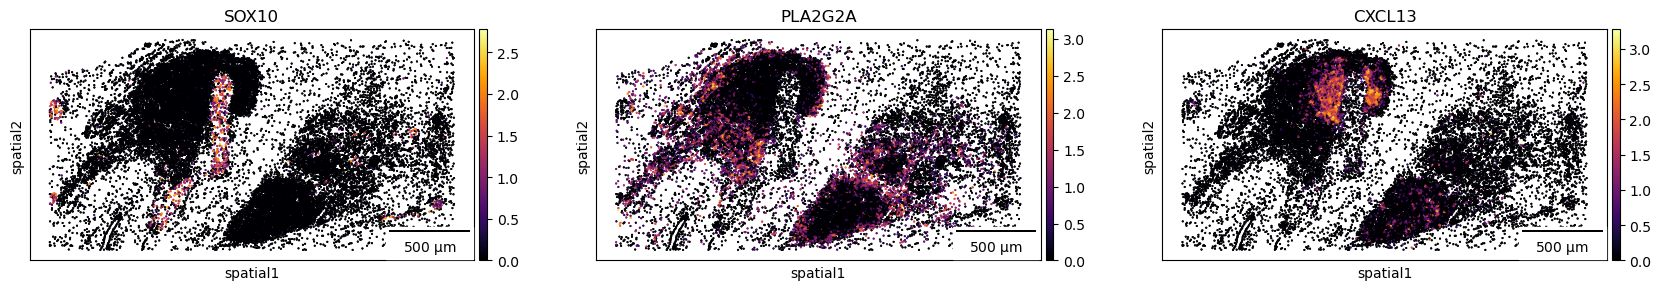

In [35]:
sq.pl.spatial_scatter(
    TLS_097_480_n2,
    library_id="spatial",
    color=['SOX10','PLA2G2A','CXCL13'],
    shape=None,
    size=1,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='Moran_#3.pdf'
)

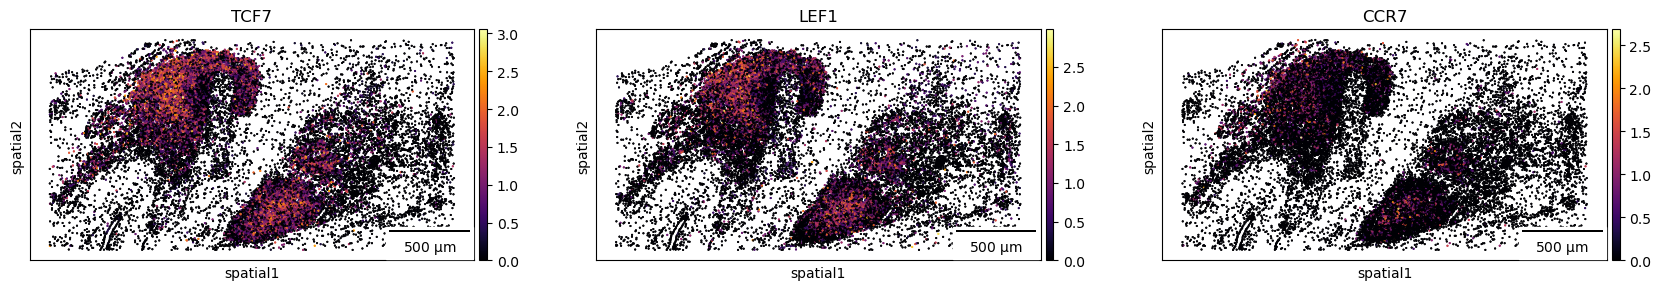

In [37]:
sq.pl.spatial_scatter(
    TLS_097_480_n2,
    library_id="spatial",
    color=['TCF7','LEF1','CCR7'],
    shape=None,
    size=1,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='Moran_#5.pdf'
)

## TLS cytokine expression

In [38]:
TLS_cytokines = ['VCAM1','CCL19','CCL21',# TLS-cytokines
                 'CXCL12',
                 'PDGFRA',
                 'CXCL14','PLA2G2A','IGF1','PDPN','MS4A1','CXCL13','CD40','BTLA',
                 'CCL22', 
                 'CD80','CD86','CD28','IL7R','TCF7','LEF1','CD274','PDCD1','TIGIT','CTLA4','ICOS','CD40LG',
                 'CCL5','PRF1','GZMA','GZMB',
                 'VWF','ACKR1','ICAM1','IL6','HAVCR2',
                 'SIGLEC1','MERTK','C1QA','C1QC',
                 ]

In [39]:
TLS_97_n3_subset = TLS_097_480_n3[TLS_097_480_n3.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells',
       'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'TAMs_C1QC' ])]

~/.local/lib/python3.9/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


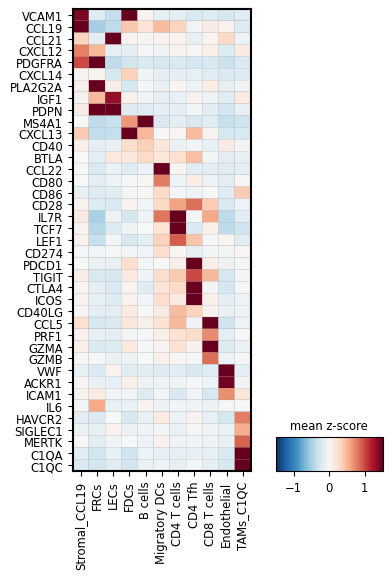

In [40]:
sc.pl.matrixplot(TLS_97_n3_subset, TLS_cytokines, groupby='TLS_cell_class_threshold', dendrogram=False,swap_axes = True,
                 colorbar_title='mean z-score', layer='scaled', vmin=-1.5, vmax=1.5, 
                 cmap='RdBu_r',  
                 categories_order = ['TRCs','FRCs','LECs','FDCs','B cells',
                                     'Migratory DCs','CD4 T cells', 'CD4 Tfh', 'CD8 T cells',
                                     'Endothelial', 'TAMs_C1QC'], 
                 figsize=(4,6), 
                )

In [41]:
TLS_96_n1_subset = TLS_096_480_n1[TLS_096_480_n1.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells',
       'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'TAMs_C1QC' ])]

~/.local/lib/python3.9/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


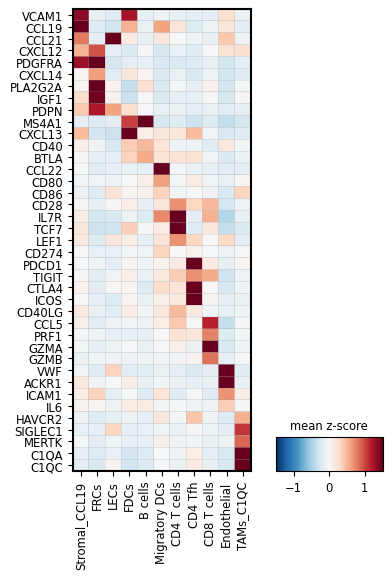

In [42]:
sc.pl.matrixplot(TLS_96_n1_subset, TLS_cytokines, groupby='TLS_cell_class_threshold', dendrogram=False,swap_axes = True,
                 colorbar_title='mean z-score', layer='scaled', vmin=-1.5, vmax=1.5, 
                 cmap='RdBu_r',  
                 categories_order = ['TRCs','FRCs','LECs','FDCs','B cells',
                                     'Migratory DCs','CD4 T cells', 'CD4 Tfh', 'CD8 T cells',
                                     'Endothelial', 'TAMs_C1QC'], 
                 figsize=(4,6))

In [43]:
SLS_subset = SLS_ref[SLS_ref.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells',
       'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'TAMs_C1QC' ])]

~/.local/lib/python3.9/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


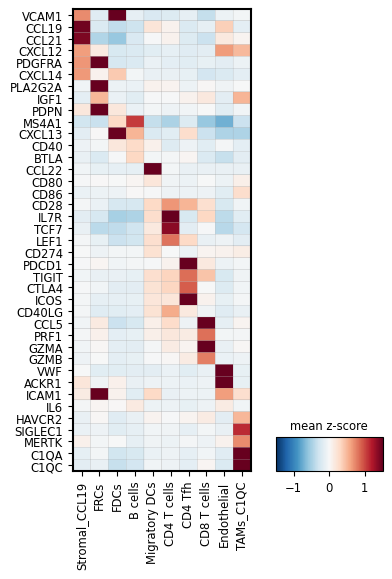

In [44]:
sc.pl.matrixplot(SLS_subset, TLS_cytokines, groupby='TLS_cell_class_threshold', dendrogram=False,swap_axes = True,
                 colorbar_title='mean z-score', layer='scaled', vmin=-1.5, vmax=1.5, 
                 #cmap = 'viridis',
                 cmap='RdBu_r',  
                 categories_order = ['TRCs','FRCs','FDCs','B cells',
                                     'Migratory DCs','CD4 T cells', 'CD4 Tfh', 'CD8 T cells',
                                     'Endothelial', 'TAMs_C1QC'], 
                 figsize=(4,6), 
                 save = 'SLS_subset.pdf'
                )

In [45]:
TNBC4 = TLS_TNBC_4[TLS_TNBC_4.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells',
       'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'MAC_SIGLEC1' ])]

In [46]:
TLS_cytokines_tnbc = ['CCL19','CCL21',# TLS-cytokines
                 #'CXCL12',#'CXCL2','IL6',
                 'PDGFRA',
                 'CXCL14','PLA2G2A','IGF1','PDPN','MS4A1','CXCL13','CD40','BTLA',
                 'CCL22', #'TNFSF14',
                 'CD80','CD86','CD28','IL7R','TCF7','LEF1','CD274','PDCD1','TIGIT','CTLA4','ICOS','CD40LG',
                 'CCL5','PRF1','GZMA','GZMB','KLRK1',
                 'VWF','ACKR1','ICAM1','IL6','HAVCR2',
                 'SIGLEC1','MERTK','C1QA','C1QC',
                 #'VSIR','SIRPA','LGALS9','TNFRSF14'
                 ]

~/.local/lib/python3.9/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


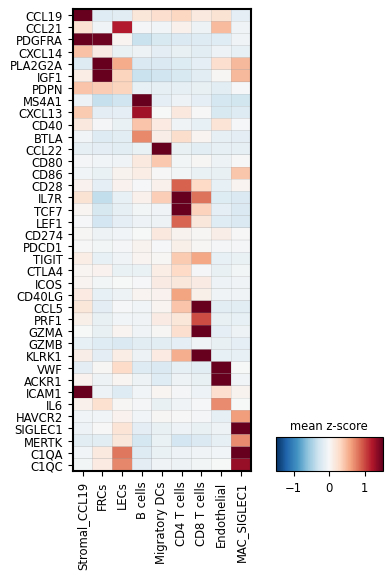

In [47]:
sc.pl.matrixplot(TNBC4, TLS_cytokines_tnbc, groupby='TLS_cell_class_threshold', dendrogram=False,swap_axes = True,
                 colorbar_title='mean z-score', layer='scaled', vmin=-1.5, vmax=1.5, 
                 #cmap = 'viridis',
                 cmap='RdBu_r',  
                 categories_order = ['TRCs','FRCs','LECs','B cells',
                                     'Migratory DCs','CD4 T cells', 'CD8 T cells',
                                     'Endothelial', 'MAC_SIGLEC1'], 
                 figsize=(4,6), 
                 #save = 'TLS_cytokines_TNBC_4.pdf'
                )

## CCL19–CCR7 and CXCL12–CXCR4

`TLS_96_n2_subset`, `TLS_97_n2_subset` and `TNBC1` were not defined in the original plotting notebook. *Assumed*: the same cell types as the n1/n3 and TNBC4 subsets above.

In [48]:
tls_subset_types = ['B cells','CD4 T cells', 'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'TAMs_C1QC' ]
TLS_96_n2_subset = TLS_096_480_n2[TLS_096_480_n2.obs['TLS_cell_class_threshold'].isin(tls_subset_types)]
TLS_97_n2_subset = TLS_097_480_n2[TLS_097_480_n2.obs['TLS_cell_class_threshold'].isin(tls_subset_types)]
TNBC1 = TLS_TNBC_1[TLS_TNBC_1.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells',
       'CD4 Tfh', 'CD8 T cells', 'Endothelial', 'FDCs', 'FRCs','LECs', 'Migratory DCs','TRCs', 'MAC_SIGLEC1' ])]

### TNBC TLS - Fig6g

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

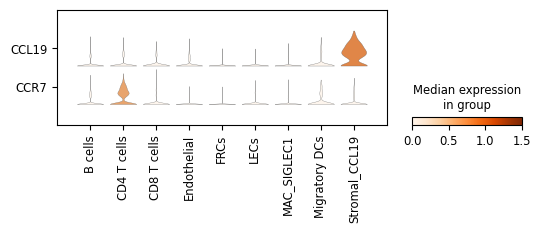

In [49]:
sc.pl.stacked_violin(
    TNBC4, ['CCL19','CCR7'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
    vmax=1.5,
    figsize=(6,1.5), 
    cmap='Oranges',
    save='Vln_TNBC4_CCL19_CCR7.pdf'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

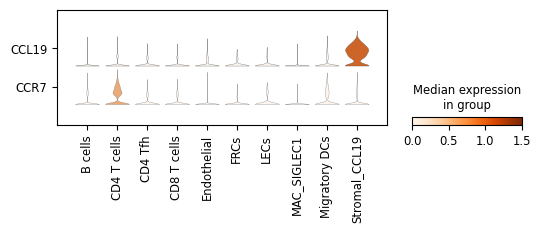

In [50]:
sc.pl.stacked_violin(
    TNBC1, ['CCL19','CCR7'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
    vmax=1.5,
    figsize=(6,1.5), 
    cmap='Oranges',
    save='Vln_TNBC1_CCL19_CCR7.pdf'
)

### PDAC TLS

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

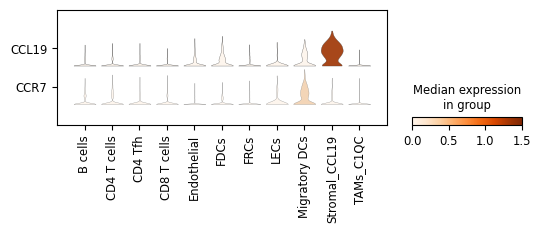

In [51]:
sc.pl.stacked_violin(
    TLS_96_n2_subset, ['CCL19','CCR7'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    save='Vln_96n2_CCL19_CCR7.pdf'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

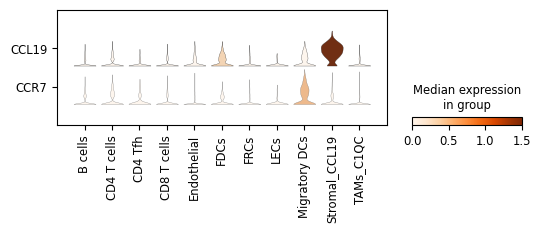

In [52]:
sc.pl.stacked_violin(
    TLS_96_n1_subset, ['CCL19','CCR7'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    save='Vln_96n1_CCL19_CCR7.pdf'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

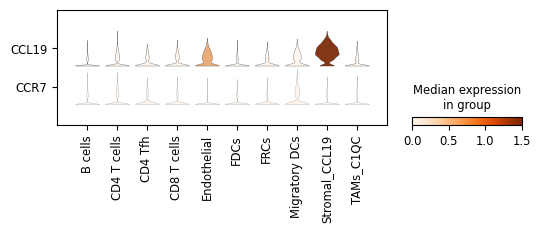

In [53]:
sc.pl.stacked_violin(
    SLS_subset, ['CCL19','CCR7'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    save='vlnplot_SLS_CCL19_CCR7.pdf'
)

### CXCL12–CXCR4

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

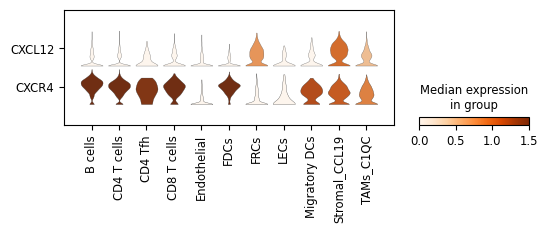

In [54]:
sc.pl.stacked_violin(
    TLS_97_n2_subset, ['CXCL12','CXCR4'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    save='Vln_97n2_CXCL12_CXCR4.pdf'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

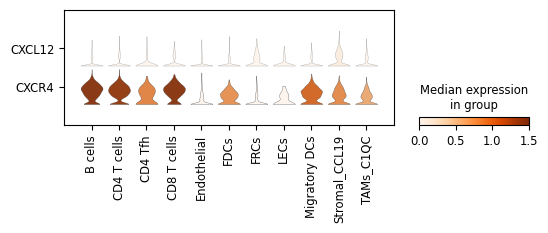

In [55]:
sc.pl.stacked_violin(
    TLS_97_n3_subset, ['CXCL12','CXCR4'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    #save='vlnplot.pdf'
)

~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:324: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _color_df = _matrix.groupby(level=0).median()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_stacked_violin.py:405: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  pd.DataFrame(_matrix.stack(dropna=False))
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or obser

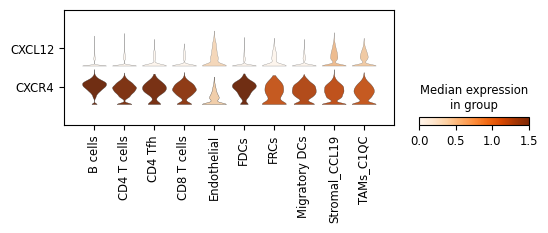

In [56]:
sc.pl.stacked_violin(
    SLS_subset, ['CXCL12','CXCR4'], groupby="TLS_cell_class_threshold", swap_axes=True, #dendrogram=True
     figsize=(6,1.5), 
    vmax=1.5,
    cmap='Oranges',
    save='vlnplot_SLS_CXCL12_CXCR4.pdf'
)

## TNBC TLS (TNBC_4)

In [57]:
TLS_TNBC_4.uns['TLS_cell_class_threshold_colors']=['#ff7f0e','#7d87b9','#536CC7','#023fa5',"#888D07","#717417", '#d62728',"#00BFA0","#535A06",
                                                     '#f79cd4', '#c5b0d5','#8c564b',
                                                     '#000035',"#105354",'#f3e1eb', "#00025E",'#d5eae7','#9cded6','#D8D18C',"#cccccc", "#B4584D",'#FFE5A7','#1b4400']

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


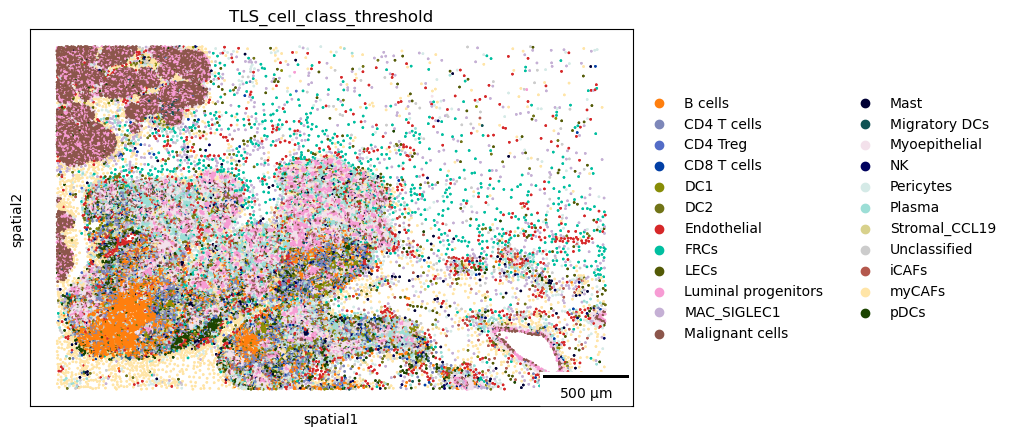

In [58]:
sq.pl.spatial_scatter(
    TLS_TNBC_4,
    library_id="spatial",
    color=['TLS_cell_class_threshold'],
    shape=None,
    size=3,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (10, 5),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    #save='Moran_#5.pdf'
)

In [59]:
genes = ['ACTA2','KRT5',
         'KIT','CDH1','KRT19','KRT7','EPCAM','ACTN4',
         'MS4A1','CD52','CXCL13','CD19',
         'IRF8','GZMB','CIITA',
         'CLEC10A','CD1C',
         'CLEC9A','IDO1',
         'LAMP3','CCL22',
         'CD8A','CD8B','GZMA',
         'NKG7','GNLY','KLRD1',
         'IL7R','TCF7',
         'FOXP3','IKZF2',
         'MZB1','PRDM1','SDC1',
         'PLVAP','VWF','KDR',
         'PDGFRB','RGS5',
         'LYVE1','FLT4','CCL21',
         'CD163','SELENOP','C1QA','C1QC','SIGLEC1',
         'PLA2G2A','IGF1','COL6A3',
         'POSTN','FN1','MMP2',
         'CPA3','KIT',
         'ICAM1','CCL19',
         'PDGFRA','C7','ABCA6','ABCA10'
        ]

         Falling back to preprocessing with `sc.pp.pca` and default params.


~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
~/.local/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:133: Fut

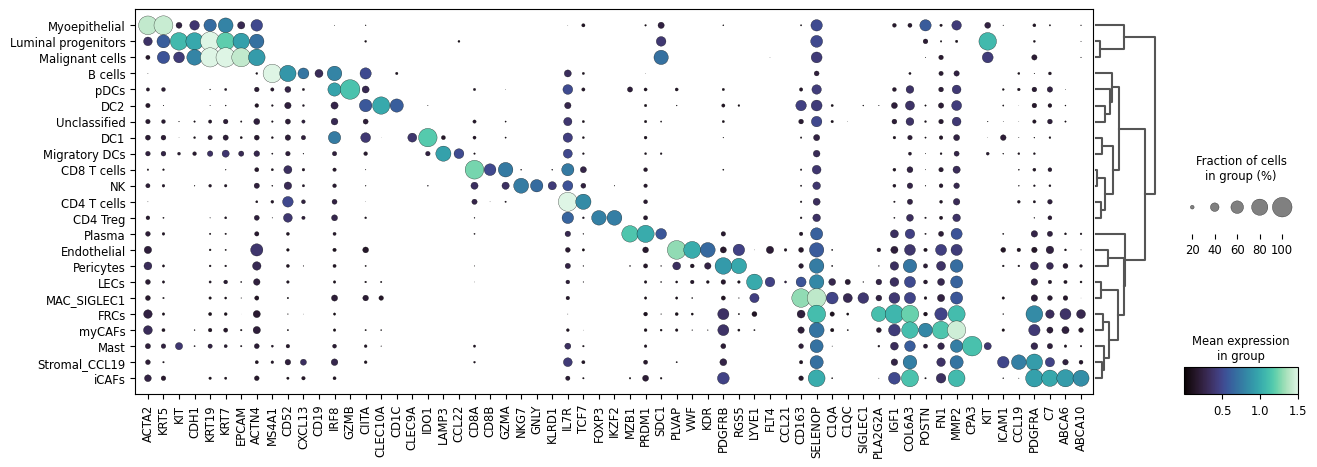

In [60]:
sc.pl.dotplot(TLS_TNBC_4, var_names = genes , groupby='TLS_cell_class_threshold', #swap_axes = True, 
              figsize=(15, 5), vmax=1.5, dot_min=0.1, cmap = 'mako',
             dendrogram=True, 
             #save = 'REP_TNBC_TLS_3962.pdf'
             )

## Scatter plot showing spatial association between B cells and lymphoid stromal cells - Extended Data Fig 9e

In [61]:
TNBC4.uns['TLS_cell_class_threshold_colors']=['#ff7f0e','#7d87b9','#7d87b9','#d62728',"#00BFA0", "#535A06",'#c5b0d5',"#105354",'#D8D18C']

/tmp/ipykernel_32965/2851179027.py:1: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  TNBC4.uns['TLS_cell_class_threshold_colors']=['#ff7f0e','#7d87b9','#7d87b9','#d62728',"#00BFA0", "#535A06",'#c5b0d5',"#105354",'#D8D18C']


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


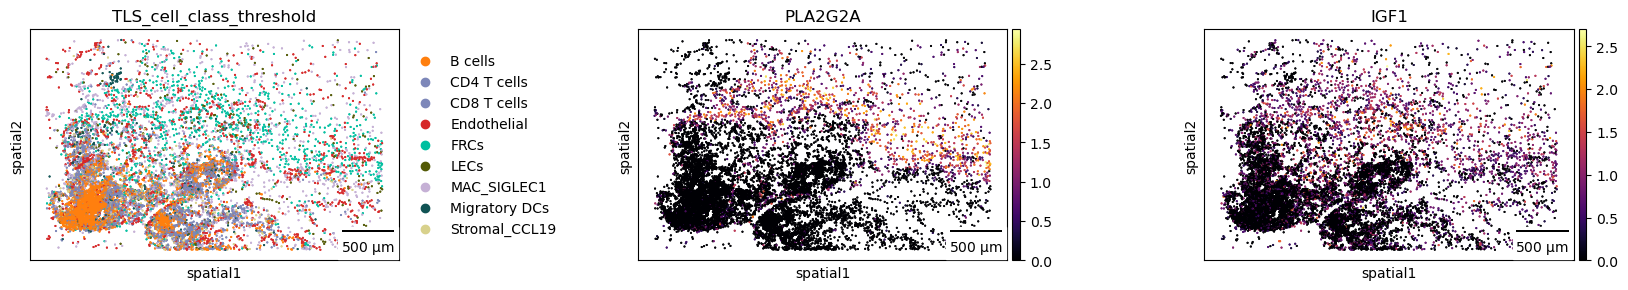

In [62]:
sq.pl.spatial_scatter(
    TNBC4,
    library_id="spatial",
    color=['TLS_cell_class_threshold','PLA2G2A','IGF1'],
    shape=None,
    size=1,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='TNBC4_TLS_PLA2G2A_IGF1.pdf'
)

In [63]:
rep4 = TNBC4[TNBC4.obs['TLS_cell_class_threshold'].isin(['B cells', 'FDCs', 'FRCs','TRCs'])]

~/.local/lib/python3.9/site-packages/squidpy/pl/_color_utils.py:26: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


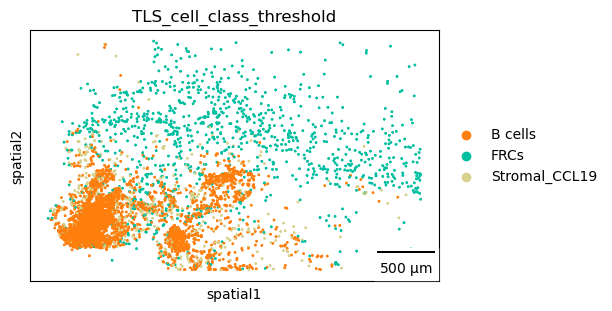

In [64]:
sq.pl.spatial_scatter(
    rep4,
    library_id="spatial",
    color=['TLS_cell_class_threshold'],
    shape=None,
    size=3,
    img=False,  cmap="inferno",
    #wspace=0.08,
    figsize = (6, 3),
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    save='TNBC_stromal.pdf'
)

/tmp/ipykernel_32965/1006010356.py:2: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  plotting.uns['TLS_cell_class_threshold_colors'] = ['#ff7f0e',"#DD51AD","#00BFA0",'#D8D18C']
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


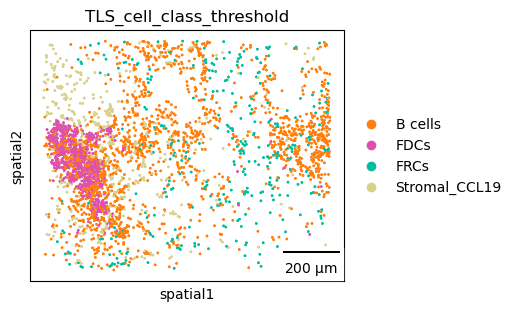

In [65]:
plotting =  TLS_096_480_n1[TLS_096_480_n1.obs['TLS_cell_class_threshold'].isin(['B cells','FDCs', 'FRCs', 'TRCs'])]
plotting.uns['TLS_cell_class_threshold_colors'] = ['#ff7f0e',"#DD51AD","#00BFA0",'#D8D18C']

sq.pl.spatial_scatter(
    plotting, shape=None, color=['TLS_cell_class_threshold'], size=3,library_id="spatial", figsize=(6, 3),
    wspace=0.8,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    crop_coord=(4000,1800,5000,2600), 
)

/tmp/ipykernel_32965/2559233502.py:2: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  plotting.uns['TLS_cell_class_threshold_colors'] = ['#ff7f0e',"#DD51AD","#00BFA0",'#D8D18C']
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


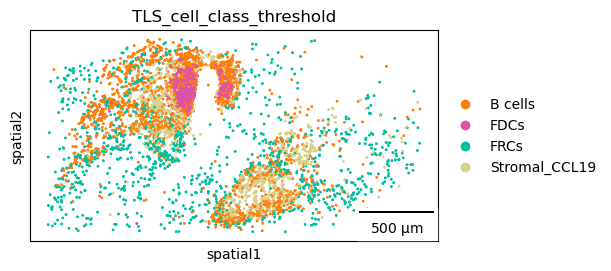

In [66]:
plotting =  TLS_097_480_n2[TLS_097_480_n2.obs['TLS_cell_class_threshold'].isin(['B cells','FDCs', 'FRCs', 'TRCs'])]
plotting.uns['TLS_cell_class_threshold_colors'] = ['#ff7f0e',"#DD51AD","#00BFA0",'#D8D18C']

sq.pl.spatial_scatter(
    plotting, shape=None, color=['TLS_cell_class_threshold'], size=3,library_id="spatial", figsize=(6, 3),
    wspace=0.8,
    scalebar_dx = 1.0,
    scalebar_kwargs={"scale_loc": "bottom", "location": "lower right"},
    #crop_coord=(4000,1800,5000,2600), 
)

## Dot plot to confirm cell identity (MH097 n2)

In [67]:
plotting_id = TLS_097_480_n2[TLS_097_480_n2.obs['TLS_cell_class_threshold'].isin(['B cells','CD4 T cells','CD8 T cells','Plasma',
         'TRCs','FDCs','FRCs',
         'Migratory DCs','DC1','DC2',
         'TAMs_C1QC','Pericytes','Endothelial','CAFs_NRT'])].copy()

         Falling back to preprocessing with `sc.pp.pca` and default params.


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
~/.local/lib/python3.9/site-packages/scanpy/tools/_dendrogram.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = rep_df.groupby(level=0).mean()


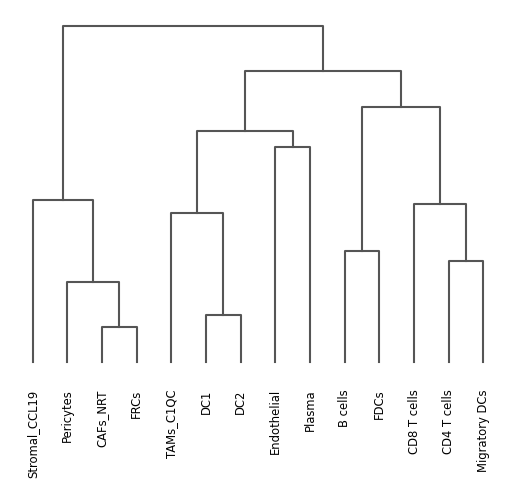

<Axes: >

In [68]:
# Running dendogram
sc.tl.dendrogram(plotting_id, groupby = "TLS_cell_class_threshold")
sc.pl.dendrogram(plotting_id, groupby = "TLS_cell_class_threshold")

In [69]:
markers = ['JCHAIN','MZB1','VWF','PLVAP',
           'ICAM1','CCL19','CXCL12',
           'PDGFRB','RGS5',
           'PDGFRA','C7','SCN7A','ABCA10','ABCA8',
           'PDPN','PLA2G2A','MEDAG','IGF1',
           'CD163','F13A1','C1QC','C1QA','SELENOP',
           'CLEC9A','IRF8','IDO1','CLNK','CD1C','CLEC10A',
           'MS4A1','CD19','CD22','VCAM1','FDCSP',
           'CD8A','CD8B','GZMA','GZMK',
           'CD4','IL7R','TCF7',
           'LAMP3','CCL22']

~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


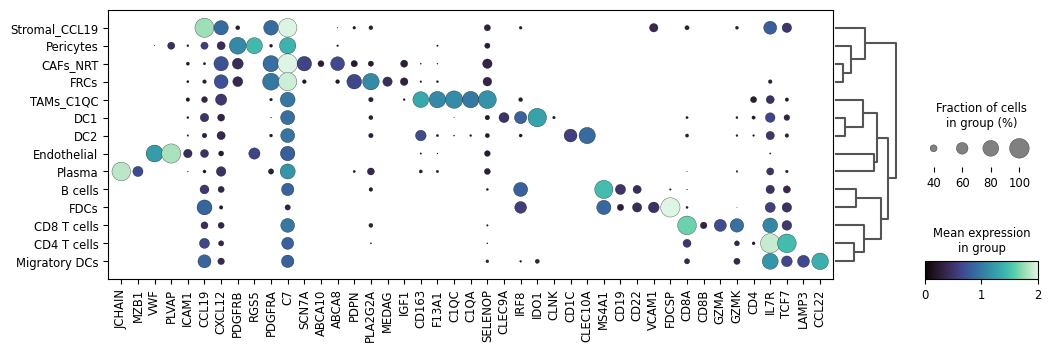

In [70]:
sc.pl.dotplot(plotting_id, var_names =markers, groupby='TLS_cell_class_threshold', swap_axes = False, 
             figsize=(12,3.5), dot_min=0.2, vmax=2.0, cmap = 'mako', save='97_n2_dotplot.pdf',
             dendrogram=True)